In [1]:
import pickle
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
VERSION=3
data_dict = pickle.load(open(f'./datas/data_v{VERSION}.pickle', 'rb'))
data = np.asarray(data_dict['data'], dtype=np.float32)
labels = np.asarray(data_dict['labels'], dtype=np.float32)

# 3. Split dataset - 80 10 10
x_train, x_temp, y_train, y_temp = train_test_split(
    data,
    labels,
    test_size=0.2,
    random_state=42
)

x_test, x_val, y_test, y_val = train_test_split(
    x_temp,
    y_temp,
    test_size=0.5,
    random_state=42
)

model = Sequential([
    Dense(128, activation='relu', input_shape=(data.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(len(np.unique(labels)), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(x_val,y_val)
)

y_probability = model.predict(x_test)
y_predict = np.argmax(y_probability, axis=1)

score = accuracy_score(y_test, y_predict)
print('{}% of samples were classified correctly !'.format(
    score * 100
))

Epoch 1/30


c:\Users\richi\OneDrive\Desktop\Richie\Deep and Machine Learning\AOL_DeepLearning_ASL\env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2356 - loss: 2.7195 - val_accuracy: 0.5462 - val_loss: 2.0945
Epoch 2/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4957 - loss: 1.7438 - val_accuracy: 0.8192 - val_loss: 1.1853
Epoch 3/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7067 - loss: 1.0765 - val_accuracy: 0.8962 - val_loss: 0.6899
Epoch 4/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8293 - loss: 0.6750 - val_accuracy: 0.9654 - val_loss: 0.4095
Epoch 5/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8865 - loss: 0.4533 - val_accuracy: 0.9577 - val_loss: 0.2660
Epoch 6/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9327 - loss: 0.3156 - val_accuracy: 0.9577 - val_loss: 0.2138
Epoch 7/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9548 - loss: 0.2344 - val_accuracy: 0.9808 - val_loss: 0.1465
Epoch 8/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9644 - loss: 0.1739 - val_accuracy: 0.9962 - val_loss: 0.1149
Epo

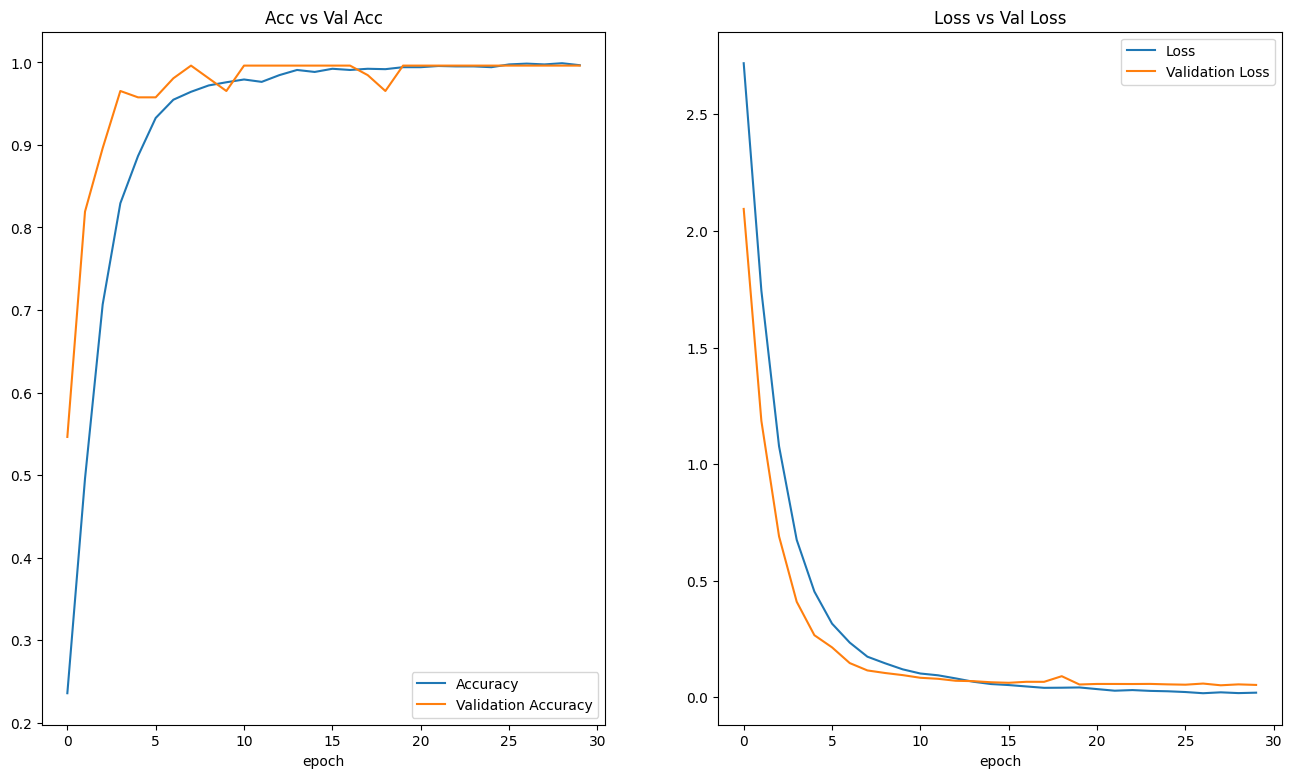

In [3]:
plt.figure(figsize=(16,9))
plt.subplot(1,2,1)
plt.title('Acc vs Val Acc')
plt.xlabel('epoch')
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.title('Loss vs Val Loss')
plt.xlabel('epoch')
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()

plt.show()

In [4]:
MODEL_VERSION = 1
while os.path.exists(f'./model/v{MODEL_VERSION}'):
    MODEL_VERSION+=1

MODEL_DIR = f'./model/v{MODEL_VERSION}/'
os.makedirs(MODEL_DIR, exist_ok=True)

model.save(f'./model/v{MODEL_VERSION}/hand_gesture_model.keras')
with open(f'./model/v{MODEL_VERSION}/labels.pickle', 'wb') as f:
    pickle.dump(labels, f)